In [1]:
import kagglehub
path = kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection")

100%|██████████| 15.1M/15.1M [00:01<00:00, 12.7MB/s]

Extracting files...


### 1. Explore and Visualize the Dataset
Let's inspect the dataset directory, list the classes, and visualize some sample MRI images (tumor vs. no tumor).

In [2]:
import os
import glob
import matplotlib.pyplot as plt
import cv2

# Define dataset directory based on downloaded path
dataset_dir = os.path.join(path, 'brain_tumor_dataset')
if not os.path.exists(dataset_dir):
    # Fallback in case directory structure is slightly different
    dataset_dir = path

print(f"Dataset Directory: {dataset_dir}")

# List subdirectories (classes)
classes = [d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]
print(f"Classes found: {classes}")

# Count images per class
for cls in classes:
    class_path = os.path.join(dataset_dir, cls)
    num_images = len(glob.glob(os.path.join(class_path, '*')))
    print(f"Class '{cls}': {num_images} images")

Dataset Directory: /root/.cache/kagglehub/datasets/navoneel/brain-mri-images-for-brain-tumor-detection/versions/1/brain_tumor_dataset
Classes found: ['yes', 'no']
Class 'yes': 155 images
Class 'no': 98 images


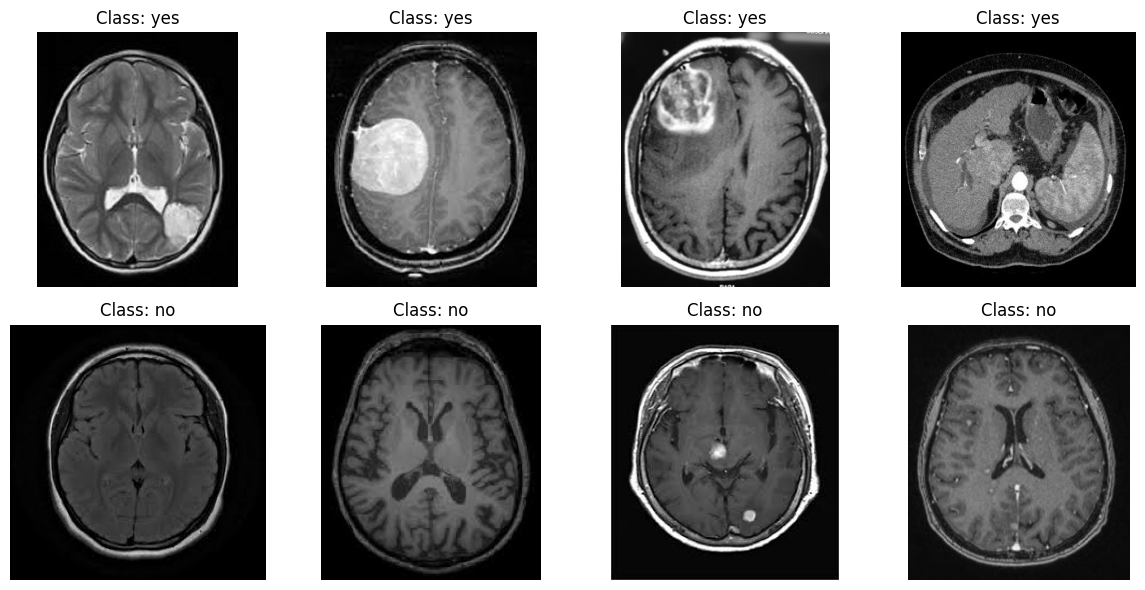

In [3]:
# Visualize sample images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, cls in enumerate(classes[:2]):
    class_path = os.path.join(dataset_dir, cls)
    img_files = glob.glob(os.path.join(class_path, '*'))[:4]
    for j, img_path in enumerate(img_files):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax = axes[i, j]
        ax.imshow(img)
        ax.set_title(f"Class: {cls}")
        ax.axis('off')
plt.tight_layout()
plt.show()

### 2. Preprocess Data and Create Datasets
We will resize all images to $224 \times 224$ pixels, normalize pixel values, and split them into training and validation sets.

In [4]:
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load training dataset
train_ds = image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

# Load validation dataset
val_ds = image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

# Prefetching for performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

Found 253 files belonging to 2 classes.
Using 203 files for training.
Found 253 files belonging to 2 classes.
Using 50 files for validation.


### 3. Build and Train the CNN Model
We will construct a Convolutional Neural Network (CNN) with a few convolutional layers, pooling layers, and a dense classification head. We also include data augmentation to prevent overfitting on this small dataset.

In [5]:
from tensorflow.keras import layers, models

# Data Augmentation layer
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
])

# Build the CNN Model
model = models.Sequential([
    # Input layer specification
    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # Rescaling pixel values to [0, 1]
    layers.Rescaling(1./255),

    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten and Dense Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Train the model
EPOCHS = 5
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 26s 4s/step - accuracy: 0.7241 - loss: 0.6001 - val_accuracy: 0.7200 - val_loss: 0.5525
Epoch 2/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - accuracy: 0.7438 - loss: 0.5478 - val_accuracy: 0.7400 - val_loss: 0.5401
Epoch 3/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 27s 4s/step - accuracy: 0.7537 - loss: 0.5420 - val_accuracy: 0.7400 - val_loss: 0.5530
Epoch 4/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 27s 4s/step - accuracy: 0.7438 - loss: 0.5549 - val_accuracy: 0.7600 - val_loss: 0.5516
Epoch 5/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 27s 4s/step - accuracy: 0.7241 - loss: 0.5747 - val_accuracy: 0.7200 - val_loss: 0.5377


### 4. Evaluate Model Performance
We will plot the accuracy and loss curves over epochs, and calculate metrics on the validation dataset.

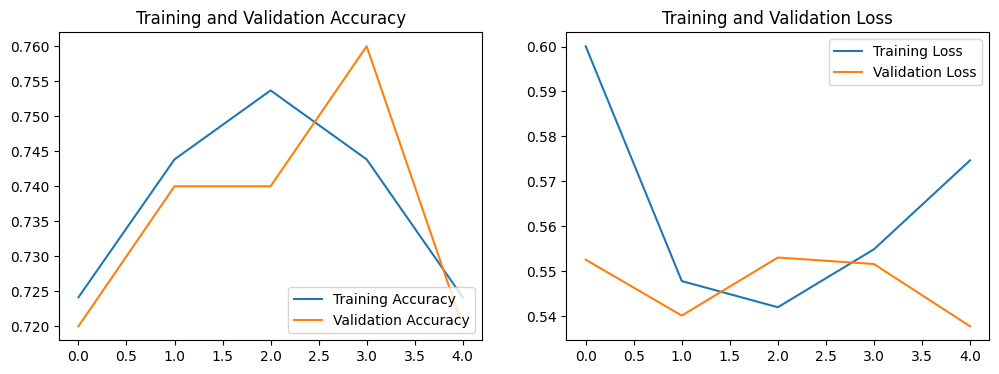

In [8]:
# Plot Training & Validation Curves
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

              precision    recall  f1-score   support

          no       0.62      0.47      0.53        17
         yes       0.76      0.85      0.80        33

    accuracy                           0.72        50
   macro avg       0.69      0.66      0.67        50
weighted avg       0.71      0.72      0.71        50



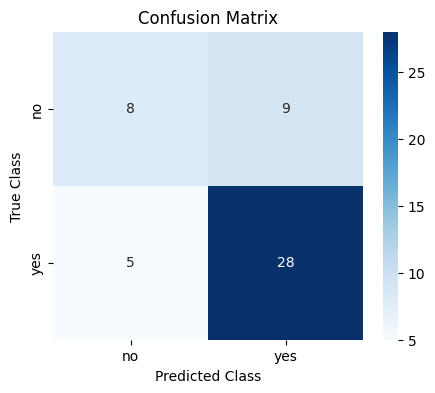

In [9]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Retrieve true labels and predictions on validation dataset
y_true = []
y_pred = []

for x, y in val_ds:
    preds = model.predict(x, verbose=0)
    y_true.extend(y.numpy().flatten())
    y_pred.extend((preds > 0.5).astype(int).flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Display classification report
print(classification_report(y_true, y_pred, target_names=sorted(classes)))

# Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=sorted(classes), yticklabels=sorted(classes))
plt.title('Confusion Matrix')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.show()

### 5. Save the Trained Model
We save our model to disk so our Streamlit application can load and use it.

In [10]:
model.save('brain_tumor_model.keras')
print("Model saved as brain_tumor_model.keras")

Model saved as brain_tumor_model.keras


### 6. Create the Streamlit Application Code
We write the Python script for the Streamlit app. Notice that the image uploader is placed inside `st.sidebar` (the left-hand input panel).

In [11]:
app_code = """
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image
import cv2

# Configure Page
st.set_page_config(page_title="Brain Tumor Detection", layout="wide")

# Cache the model loader
@st.cache_resource
def load_brain_tumor_model():
    return tf.keras.models.load_model('brain_tumor_model.keras')

try:
    model = load_brain_tumor_model()
    model_loaded = True
except Exception as e:
    st.error(f"Error loading model: {e}")
    model_loaded = False

# Left Side Input Panel (Sidebar)
st.sidebar.title("Input Panel")
st.sidebar.write("Upload a Brain MRI image to scan for brain tumors.")

uploaded_file = st.sidebar.file_uploader("Choose a Brain MRI Image...", type=["jpg", "jpeg", "png", "webp"])

# Main Panel
st.title("🧠 Brain Tumor Detection Application")
st.write("This system uses a Deep Learning Convolutional Neural Network (CNN) to predict if an MRI contains a brain tumor.")

if uploaded_file is not None:
    # Open and display the uploaded image
    image = Image.open(uploaded_file)

    col1, col2 = st.columns([1, 1])

    with col1:
        st.subheader("Uploaded Brain MRI")
        st.image(image, use_column_width=True)

    with col2:
        st.subheader("Diagnostic Analysis")
        if model_loaded:
            # Convert image to RGB (handles grayscale or RGBA)
            img_rgb = image.convert('RGB')
            # Resize image to match model input
            img_resized = img_rgb.resize((224, 224))
            # Convert to array and expand dimensions
            img_array = np.array(img_resized)
            img_batch = np.expand_dims(img_array, axis=0)

            # Make prediction
            with st.spinner("Analyzing image..."):
                prediction = model.predict(img_batch)[0][0]

            # Show metric results
            if prediction > 0.5:
                st.error(f"🚨 Prediction: Tumor Detected (Confidence: {prediction * 100:.2f}%)")
                st.warning("Disclaimer: This tool is for educational/informational purposes only. Please consult a medical professional for accurate diagnoses.")
            else:
                st.success(f"✅ Prediction: No Tumor Detected (Confidence: {(1 - prediction) * 100:.2f}%)")
                st.info("Disclaimer: This tool is for educational/informational purposes only. Please consult a medical professional for accurate diagnoses.")
        else:
            st.warning("Model is not loaded. Please verify 'brain_tumor_model.keras' exists.")
else:
    st.info("👈 Please upload a brain MRI scan image in the left panel to begin the analysis.")
"""

with open('app.py', 'w') as f:
    f.write(app_code)
print("Streamlit app script saved as app.py")

Streamlit app script saved as app.py


In [13]:
!pip install --ignore-installed blinker
!pip install streamlit

  Using cached streamlit-1.65.0-py3-none-any.whl.metadata (10 kB)
Using cached streamlit-1.65.0-py3-none-any.whl (10.3 MB)


In [14]:
!pip install streamlit pyngrok

In [15]:
from pyngrok import ngrok
ngrok.set_auth_token("3H2nxZtP4iC5L9tX9K97OPLut9W_4JsZrRVF5aRFQpQCCePy1")

In [16]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print(public_url)

NgrokTunnel: "https://vanity-amperage-commodore.ngrok-free.dev" -> "http://localhost:8501"


In [17]:
# Run the Streamlit app
# This will provide a public URL to access the app
!streamlit run app.py &


2026-10-10 09:07:18.118 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.147.95.237:8501

I0000 00:00:1791623242.468034    3335 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791623246.422271    3335 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1791623248.613709    3335 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
2026-10-10 09:08:34.531 `use_column_width` was removed and has no effect. Use `width='stretch'`, `width='content'`, or an integer pixel value instead.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step
2026-10-10 09:08:59.336 `use_column_width` was removed and has no effect. Use `width='stretch'`, `width='content'`, or an integer pixel value instead.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms

### 7. Run and Expose the Streamlit App
We install Streamlit and use `localtunnel` to generate a secure public URL so you can interact with your application.

In [12]:
!pip install -q streamlit
!npm install -g localtunnel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 92.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 104.9 MB/s eta 0:00:00
ERROR: Operation cancelled by user
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 455, in run
^C
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋
added 22 packages in 2s
⠙
⠙3 packages are looking for funding
⠙  run `npm fund` for details
⠙

In [ ]:
# Get IP Address of Colab instance (required password/tunnel authentication password for localtunnel)
import urllib
print("Use this IP as password if prompted by localtunnel: ", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip())

In [ ]:
# Launch Streamlit and start localtunnel
import subprocess
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501"])
!npx localtunnel --port 8501